# ARTI406 - Image Processing
## Lab 5: Spatial Filtering - Smoothing and Sharpening

Just run every cell top to bottom (Run All). Nothing to type or download by hand — the first cell installs the required packages and pulls `Parrot.png` via `curl` into an `images` folder.

### Step 0: Install packages and download the sample image (run once)

In [1]:
%pip install -q opencv-python numpy matplotlib

import os

images_dir = os.path.join(os.getcwd(), 'images')
os.makedirs(images_dir, exist_ok=True)

url = 'https://raw.githubusercontent.com/PacktPublishing/Hands-On-Image-Processing-with-Python/master/images/parrot.png'
dest = os.path.join(images_dir, 'Parrot.png')

!curl -L -s -o "{dest}" "{url}"
size = os.path.getsize(dest) if os.path.exists(dest) else 0
print(f'Parrot.png: {"OK" if size > 0 else "FAILED"} ({size} bytes) -> {dest}')

Note: you may need to restart the kernel to use updated packages.
Parrot.png: OK (215272 bytes) -> c:\Users\mhtan\Desktop\image processing\lab5\images\Parrot.png


## Task#1: Unsharp Masking

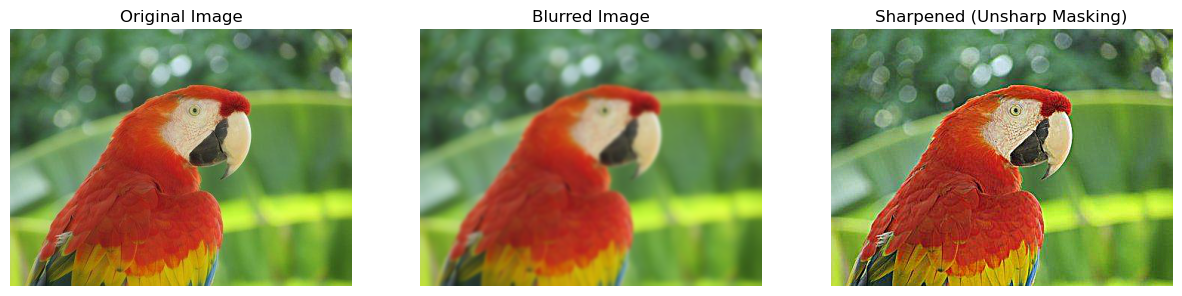

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read the image
image = cv2.imread(os.path.join('images', 'Parrot.png'))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB

# Gaussian sigma
sigma = 2

# parameter
amount = 1.5

# Convert image to float32 for processing
image_float = image.astype(np.float32) / 255.0

# Apply Gaussian blur
blurred = cv2.GaussianBlur(image_float, (0, 0), sigmaX=sigma, sigmaY=sigma)

# Perform Unsharp Masking
sharpened = np.clip(image_float + amount * (image_float - blurred), 0, 1)

# Plot original, blurred, and sharpened images
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image)
ax[0].set_title('Original Image')
ax[0].axis('off')

ax[1].imshow(blurred)
ax[1].set_title('Blurred Image')
ax[1].axis('off')

ax[2].imshow(sharpened)
ax[2].set_title('Sharpened (Unsharp Masking)')
ax[2].axis('off')

plt.show()

## Assessment

### Task#1: Convolve an image with a 7x7 box filter, and output the original and smoothed image side by side

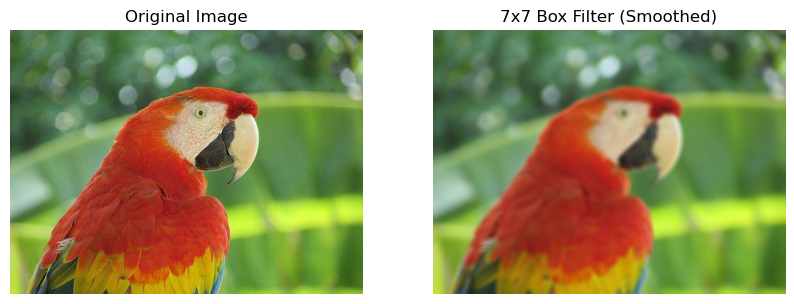

In [3]:
# A box filter is a simple averaging filter: every pixel in the 7x7 neighborhood
# contributes equally (1/49) to the output pixel.
box_kernel = np.ones((7, 7), np.float32) / 49
box_filtered = cv2.filter2D(image, -1, box_kernel)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(image)
ax[0].set_title('Original Image')
ax[0].axis('off')

ax[1].imshow(box_filtered)
ax[1].set_title('7x7 Box Filter (Smoothed)')
ax[1].axis('off')

plt.show()

### Task#2: Apply a 5x5 Gaussian filter and a 21x21 Gaussian filter, and show the three images side by side

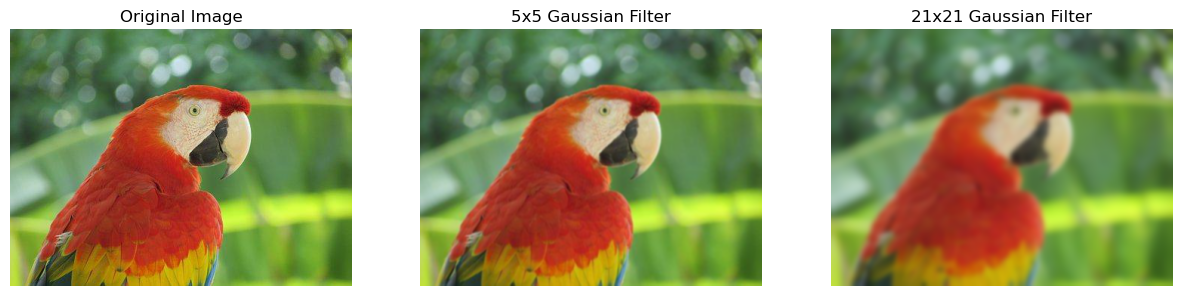

In [4]:
gaussian_5x5 = cv2.GaussianBlur(image, (5, 5), sigmaX=0)
gaussian_21x21 = cv2.GaussianBlur(image, (21, 21), sigmaX=0)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image)
ax[0].set_title('Original Image')
ax[0].axis('off')

ax[1].imshow(gaussian_5x5)
ax[1].set_title('5x5 Gaussian Filter')
ax[1].axis('off')

ax[2].imshow(gaussian_21x21)
ax[2].set_title('21x21 Gaussian Filter')
ax[2].axis('off')

plt.show()

### Task#3: Apply a 3x3 Laplacian filter to sharpen the image

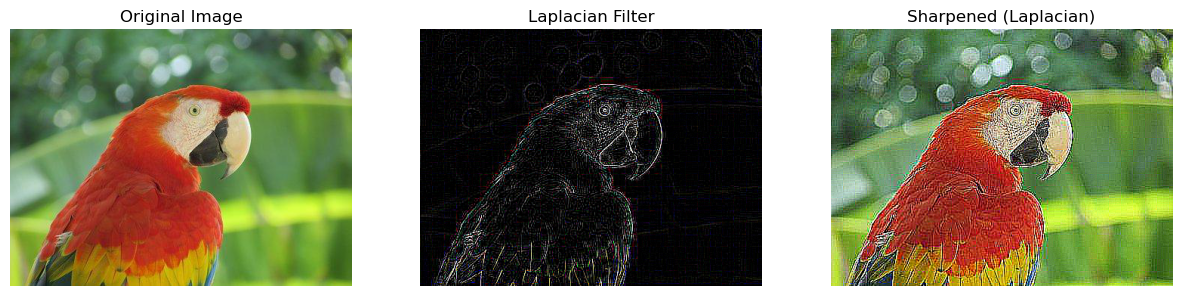

In [5]:
# 1. Read the image (reuse the one already loaded as `image`, in RGB)

# 2. Convert image to float32
image_float = image.astype(np.float32) / 255.0

# 3. Use the cv2.Laplacian() function (ksize=3 -> 3x3 Laplacian)
laplacian = cv2.Laplacian(image_float, cv2.CV_32F, ksize=3)

# 4. Sharpen the image
laplacian_sharpened = np.clip(image_float - laplacian, 0, 1)

# 5. Plot the original image, the Laplacian result, and the sharpened image
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image_float)
ax[0].set_title('Original Image')
ax[0].axis('off')

ax[1].imshow(np.clip(laplacian, 0, 1))
ax[1].set_title('Laplacian Filter')
ax[1].axis('off')

ax[2].imshow(laplacian_sharpened)
ax[2].set_title('Sharpened (Laplacian)')
ax[2].axis('off')

plt.show()